# Counting Islands — Classical Algorithms & Scalable Systems Design

## 1. Problem Statement & Formal Requirements Analysis

### Problem Description
Given an $M \times N$ binary matrix representing a geographic map where:
- `1` denotes **land** (part of an island),
- `0` denotes **ocean** (water),

compute the total number of distinct islands in the most efficient and scalable way possible.

### Formal Graph-Theoretic Formulation
We can model the matrix $A \in \{0, 1\}^{M \times N}$ as an undirected grid graph $G = (V, E)$:
- **Vertices**: $V = \{(r, c) \mid 0 \le r < M,\; 0 \le c < N,\; A[r][c] = 1\}$.
- **Edges**: Two land vertices $(r_1, c_1), (r_2, c_2) \in V$ share an undirected edge iff they are adjacent under the problem's connectivity rule.
- **Objective**: Compute the number of connected components in $G$.

### Critical Specification Deduction from Test Cases (4-Connectivity vs. 8-Connectivity)
The prompt explicitly cautions: *"Take care that you clearly understand test cases before starting implementation."* Inspecting the provided test cases resolves the most important ambiguity in grid problems — **neighborhood connectivity**:

| Test Case | Dimensions ($M \times N$) | Matrix | Expected Output | Structural Deduction |
| :--- | :---: | :--- | :---: | :--- |
| **Case 1** | $3 \times 3$ | `0 1 0` / `0 0 0` / `0 1 1` | **2** | Standard orthogonal grouping: `(0,1)` is 1 island; `(2,1)-(2,2)` is 1 island. |
| **Case 2** | $3 \times 4$ | `0 0 0 1` / `0 0 1 0` / `0 1 0 0` | **3** | **Decisive proof of 4-connectivity**: `(0,3)`, `(1,2)`, and `(2,1)` are diagonally adjacent yet count as **3 separate islands** (under 8-connectivity the answer would be 1). |
| **Case 3** | $3 \times 4$ | `0 0 0 1` / `0 0 1 1` / `0 1 0 1` | **2** | Confirms 4-connectivity: `{(0,3), (1,2), (1,3), (2,3)}` forms one connected component, while `(2,1)` is only diagonally touching `(1,2)` and remains a separate island. |

**Conclusion**: Connectivity is strictly **4-directional (orthogonal / von Neumann neighborhood)**:
$$N_4(r, c) = \{(r-1, c),\; (r+1, c),\; (r, c-1),\; (r, c+1)\}$$

### Edge Cases & Production Constraints
A production-grade solution must cleanly handle:
1. **Degenerate dimensions**: Empty grid ($M = 0$ or $N = 0$), single cell ($1 \times 1$), 1D strips ($1 \times N$ or $M \times 1$).
2. **Extremal densities**: All water (`0` islands), all land (`1` island), checkerboard pattern (maximum theoretical islands = $\lceil M \cdot N / 2 \rceil$).
3. **Adversarial topologies**: Long snake/spiral paths (path length $\Theta(MN)$ that trigger stack overflow in recursive DFS) and U-shaped / comb-shaped basins (requiring transitive merging of previously separate components).
4. **Input immutability & scale**: Avoiding destructive side effects on caller-owned data, and supporting grids too large to fit into RAM via row-by-row streaming.

## 2. Algorithmic Complexity & Architectural Trade-Off Analysis

Any exact algorithm must inspect every cell at least once in the worst case, establishing a strict **information-theoretic lower bound of $\Omega(MN)$ time**. The key engineering differentiators are **auxiliary memory**, **stack safety**, **input immutability**, **Python interpreter overhead**, and **out-of-core / distributed scalability**.

| Approach | Time Complexity | Auxiliary Space | Mutates Input? | Stack-Safe? | Streaming / Out-of-Core? | Engineering Verdict |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| **Recursive DFS** | $O(MN)$ | $O(MN)$ call stack | Optional | **No** (`RecursionError` at ~1,000 depth) | No | **Rejected** for production. |
| **Iterative DFS (Stack)** | $O(MN)$ | $O(MN)$ worst-case stack | Yes (or $O(MN)$ visited) | Yes | No | Suboptimal peak space on spiral/snake grids. |
| **Iterative BFS (In-Place)** | $O(MN)$ | **$O(\min(M, N))$** | Yes | Yes | No | **Optimal in-memory** when mutation is permitted (wavefront diameter $\le \min(M, N) + 1$). |
| **Iterative BFS (Flat Bit/Bytearray)** | $O(MN)$ | $O(MN)$ bits/bytes $+ O(\min(M, N))$ | **No** | Yes | No | Best non-destructive in-memory graph traversal; ~100x leaner than `set[(r, c)]`. |
| **Streaming Bounded-Memory DSU (Row Compaction)** | $O(MN \cdot \alpha(N))$ | **$O(N)$ strictly** | **No** | Yes | **Yes** | **Flagship scalable solution**: $O(N)$ RAM independent of $M$, single-pass, zero mutation, generalizes to distributed MapReduce/Spark. |

### Why Two Solutions Are Provided
1. **Solution 1 (`count_islands_bfs`)**: Optimal in-memory **Iterative BFS** using integer-packed flat indices (`idx = r * cols + c`) to eliminate Python `(r, c)` tuple allocations in the hot loop, supporting both $O(\min(M, N))$ in-place mode and compact `bytearray` immutable mode.
2. **Solution 2 (`StreamingIslandCounter` / `count_islands_streaming_dsu`)**: **Single-Pass Streaming Disjoint Set Union (Union-Find) with Row-Level Label Compaction** (a bounded-memory variant of the Hoshen-Kopelman algorithm). By re-indexing active component roots after each row, DSU memory stays strictly bounded by $O(N)$ regardless of how many millions of rows $M$ are streamed.

> **Inverse Ackermann Bound**: With Path Compression + Union by Rank, $\alpha(N) \le 4$ for any $N \le 2^{65536}$, making the streaming DSU effectively $O(MN)$ in practice.

## 3. Environment Setup & Zero-Dependency Core Imports

The core algorithmic implementations rely **strictly on the Python 3 standard library** (`collections.deque`, `typing`, `io`) so they can be deployed directly into any production service, CLI tool, or interview harness with zero external dependency overhead.

Optional scientific libraries (`numpy`, `scipy`, `matplotlib`) are imported defensively below solely for **differential oracle verification** (`scipy.ndimage.label`) and **benchmark visualization**.

In [1]:
from __future__ import annotations

import io
import random
import time
import tracemalloc
from collections import deque
from collections.abc import Iterable, Iterator, Sequence
from typing import Literal, TextIO

# Optional scientific stack used ONLY for differential testing & visualization.
try:
    import matplotlib.pyplot as plt
    HAS_MATPLOTLIB = True
except ImportError:
    HAS_MATPLOTLIB = False

try:
    import numpy as np
    from scipy.ndimage import label as scipy_label
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False

print(f"Environment ready | matplotlib={HAS_MATPLOTLIB} | scipy_oracle={HAS_SCIPY}")

Environment ready | matplotlib=True | scipy_oracle=True


## 4. Defensive Input Parsing & Validation Layer

In production systems and automated grading harnesses, I/O parsing must be decoupled from core algorithmic logic:
- **`parse_grid_from_stream`**: Parses the exact specification format (`M N` followed by `M` rows of `N` space-separated binary values) into an in-memory 2D list with strict validation.
- **`iter_grid_rows_from_stream`**: A **lazy generator** yielding one validated row at a time. When paired with `count_islands_streaming_dsu`, an arbitrarily large input file (e.g., $10^7 \times 10^3$) can be processed in **$O(N)$ peak RAM** without ever loading the full matrix into memory.
- **`validate_grid`**: Enforces rectangularity and binary state invariants (`0` or `1`) on in-memory matrices, failing fast with descriptive `ValueError` messages on malformed input.

In [2]:
def validate_grid(grid: Sequence[Sequence[int]]) -> tuple[int, int]:
    """Validate that a 2D sequence is a rectangular binary matrix.

    Args:
        grid: Two-dimensional sequence containing integer states 0 (ocean) or 1 (land).

    Returns:
        A tuple ``(rows, cols)`` representing the validated dimensions. Returns ``(0, 0)``
        for empty inputs such as ``[]`` or ``[[]]``.

    Raises:
        ValueError: If rows have inconsistent lengths or contain values outside ``{0, 1}``.
    """
    rows = len(grid)
    if rows == 0:
        return 0, 0

    cols = len(grid[0])
    if cols == 0:
        for r_idx, row in enumerate(grid):
            if len(row) != 0:
                raise ValueError(
                    f"Jagged matrix detected at row {r_idx}: expected length 0, got {len(row)}."
                )
        return 0, 0

    for r_idx, row in enumerate(grid):
        if len(row) != cols:
            raise ValueError(
                f"Jagged matrix detected at row {r_idx}: expected length {cols}, got {len(row)}."
            )
        for c_idx, val in enumerate(row):
            if val not in (0, 1):
                raise ValueError(
                    f"Invalid cell value {val!r} at ({r_idx}, {c_idx}); expected 0 or 1."
                )

    return rows, cols


def iter_grid_rows_from_stream(stream: TextIO) -> tuple[int, int, Iterator[list[int]]]:
    """Parse header dimensions and return a lazy row iterator over a text stream.

    Expected stream format:
        Line 1: ``M N`` (non-negative integers)
        Next M lines: ``N`` whitespace-separated integers in ``{0, 1}``

    Args:
        stream: Readable text stream (e.g., ``sys.stdin``, file object, or ``io.StringIO``).

    Returns:
        A tuple ``(rows, cols, row_iterator)`` where ``row_iterator`` yields each row
        lazily in O(N) memory.

    Raises:
        ValueError: If header or row data is missing, malformed, or out of domain.
    """
    header_line = ""
    for line in stream:
        stripped = line.strip()
        if stripped:
            header_line = stripped
            break

    if not header_line:
        return 0, 0, iter(())

    header_parts = header_line.split()
    if len(header_parts) != 2:
        raise ValueError(
            f"Invalid header {header_line!r}: expected two integers 'M N'."
        )

    rows, cols = int(header_parts[0]), int(header_parts[1])
    if rows < 0 or cols < 0:
        raise ValueError(f"Matrix dimensions must be non-negative, got ({rows}, {cols}).")

    def _row_generator() -> Iterator[list[int]]:
        read_rows = 0
        for line in stream:
            stripped = line.strip()
            if not stripped:
                continue
            values = [int(tok) for tok in stripped.split()]
            if len(values) != cols:
                raise ValueError(
                    f"Row {read_rows} has {len(values)} columns; expected {cols}."
                )
            for c_idx, val in enumerate(values):
                if val not in (0, 1):
                    raise ValueError(
                        f"Invalid cell value {val!r} at ({read_rows}, {c_idx}); expected 0 or 1."
                    )
            yield values
            read_rows += 1
            if read_rows == rows:
                break

        if read_rows != rows:
            raise ValueError(f"Expected {rows} rows from stream, but received {read_rows}.")

    return rows, cols, _row_generator()


def parse_grid_from_stream(stream: TextIO) -> tuple[int, int, list[list[int]]]:
    """Materialize a full 2D binary matrix from a text stream.

    Args:
        stream: Readable text stream formatted as ``M N`` followed by ``M`` rows.

    Returns:
        A tuple ``(rows, cols, grid)``.
    """
    rows, cols, row_iter = iter_grid_rows_from_stream(stream)
    return rows, cols, list(row_iter)

## 5. Solution 1: Optimal In-Memory Iterative BFS (`count_islands_bfs`)

### Engineering Optimizations Applied
1. **Wavefront Memory Bound ($O(\min(M, N))$)**: Unlike iterative DFS (which can accumulate $O(MN)$ vertices on a spiral/snake path), BFS expands radially in Manhattan-distance shells. The maximum frontier size on an $M \times N$ grid is strictly bounded by $\min(M, N) + 1$.
2. **Flat Integer Indexing (`idx = r * cols + c`)**: Storing a single integer in `collections.deque` instead of a 2-tuple `(r, c)` eliminates per-cell Python tuple heap allocations and reduces GC pressure in the inner loop.
3. **Compact Immutable Mode (`bytearray`)**: When `mutate_in_place=False` (default for clean, side-effect-free APIs), visited states are stored in a flat `bytearray(rows * cols)` — exactly **1 byte per cell** in contiguous memory, compared to ~100+ bytes per entry in a Python `set[tuple[int, int]]`.
4. **Mark-on-Enqueue Invariant**: Each neighbor is marked visited **immediately upon enqueuing** (not upon popping), guaranteeing each cell enters the queue at most once and preventing quadratic duplicate-enqueue blowups.

### Complexity
- **Time**: $O(M \cdot N)$ — each cell is scanned once in the outer loop and enqueued/dequeued at most once.
- **Auxiliary Space**:
  - `mutate_in_place=True`: **$O(\min(M, N))$** (queue only).
  - `mutate_in_place=False`: **$O(M \cdot N)$ bytes** (`bytearray` of size $MN$ bytes) $+ O(\min(M, N))$ queue.

In [3]:
def count_islands_bfs(
    grid: Sequence[Sequence[int]],
    *,
    mutate_in_place: bool = False,
    validate: bool = True,
) -> int:
    """Count 4-connected islands in a binary grid using Iterative BFS.

    Uses flat integer indices (``r * cols + c``) inside ``collections.deque`` to
    avoid per-cell tuple allocations in the hot traversal loop.

    Args:
        grid: 2D binary sequence where ``1`` represents land and ``0`` represents ocean.
            Must be mutable (e.g., ``list[list[int]]``) if ``mutate_in_place=True``.
        mutate_in_place: If True, sinks visited land cells (sets ``1 -> 0``) directly
            in ``grid`` to achieve strict O(min(M, N)) auxiliary space. Defaults to False
            to preserve input immutability.
        validate: If True, runs ``validate_grid`` before traversal. Set to False only
            when inputs are pre-validated in tight benchmarks.

    Returns:
        Total number of 4-connected islands.
    """
    if validate:
        rows, cols = validate_grid(grid)
    else:
        rows = len(grid)
        cols = len(grid[0]) if rows > 0 else 0

    if rows == 0 or cols == 0:
        return 0

    islands = 0
    queue: deque[int] = deque()
    last_row = rows - 1
    last_col = cols - 1

    if mutate_in_place:
        # In-place path: O(min(M, N)) auxiliary space, mutates caller's grid.
        mutable_grid: list[list[int]] = grid  # type: ignore[assignment]
        for r in range(rows):
            row_ref = mutable_grid[r]
            for c in range(cols):
                if row_ref[c] == 1:
                    islands += 1
                    row_ref[c] = 0  # Mark-on-enqueue invariant
                    queue.append(r * cols + c)

                    while queue:
                        idx = queue.popleft()
                        cr, cc = divmod(idx, cols)

                        # Up
                        if cr > 0 and mutable_grid[cr - 1][cc] == 1:
                            mutable_grid[cr - 1][cc] = 0
                            queue.append(idx - cols)
                        # Down
                        if cr < last_row and mutable_grid[cr + 1][cc] == 1:
                            mutable_grid[cr + 1][cc] = 0
                            queue.append(idx + cols)
                        # Left
                        if cc > 0 and mutable_grid[cr][cc - 1] == 1:
                            mutable_grid[cr][cc - 1] = 0
                            queue.append(idx - 1)
                        # Right
                        if cc < last_col and mutable_grid[cr][cc + 1] == 1:
                            mutable_grid[cr][cc + 1] = 0
                            queue.append(idx + 1)
        return islands

    # Immutable path: contiguous flat bytearray (1 byte/cell) avoids mutating input.
    visited = bytearray(rows * cols)
    for r in range(rows):
        row_ref = grid[r]
        row_offset = r * cols
        for c in range(cols):
            start_idx = row_offset + c
            if row_ref[c] == 1 and not visited[start_idx]:
                islands += 1
                visited[start_idx] = 1
                queue.append(start_idx)

                while queue:
                    idx = queue.popleft()
                    cr, cc = divmod(idx, cols)

                    # Up
                    if cr > 0:
                        up_idx = idx - cols
                        if not visited[up_idx] and grid[cr - 1][cc] == 1:
                            visited[up_idx] = 1
                            queue.append(up_idx)
                    # Down
                    if cr < last_row:
                        down_idx = idx + cols
                        if not visited[down_idx] and grid[cr + 1][cc] == 1:
                            visited[down_idx] = 1
                            queue.append(down_idx)
                    # Left
                    if cc > 0:
                        left_idx = idx - 1
                        if not visited[left_idx] and grid[cr][cc - 1] == 1:
                            visited[left_idx] = 1
                            queue.append(left_idx)
                    # Right
                    if cc < last_col:
                        right_idx = idx + 1
                        if not visited[right_idx] and grid[cr][cc + 1] == 1:
                            visited[right_idx] = 1
                            queue.append(right_idx)

    return islands

## 6. Solution 2 (Flagship Scalable): Streaming Bounded-Memory Union-Find with Row Compaction

### Why This Algorithm Matters at Big-Tech Scale
Consider a high-resolution satellite raster or geospatial occupancy map of size $10^6 \times 10^4$ ($10^{10}$ cells). Loading the entire matrix into Python RAM is infeasible, and mutating upstream read-only storage is impossible.

### Algorithmic Mechanics (Single-Pass Row-Scan DSU + Label Compaction)
We process the grid **strictly one row at a time** from any `Iterable[Sequence[int]]`:
1. Maintain `prev_labels` (length $N$): stores the compacted component ID (`0 .. K-1`) of each cell in the previous row, or `-1` for ocean.
2. Maintain a lightweight Disjoint Set Union (Union-Find) over the active labels in the current frontier, using **Path Halving** and **Union by Rank**.
3. For each cell `c` in `curr_row`:
   - If `curr_row[c] == 0`: `curr_labels[c] = -1`.
   - If `curr_row[c] == 1`: inspect only its already-processed causal neighbors — **left** (`curr_labels[c - 1]`) and **up** (`prev_labels[c]`):
     - **Neither is land**: allocate a new component ID in the DSU and increment `island_count += 1`.
     - **Exactly one is land**: inherit its label (part of an existing island).
     - **Both are land**: `union(left, up)`. If they belonged to **distinct** roots (e.g., closing the bottom of a U-shaped island), merge them and decrement `island_count -= 1`.
4. **Bounded-Memory Guarantee — End-of-Row Label Compaction**:
   - Without compaction, a naive DSU accumulates $O(MN)$ entries in its `parent` array.
   - At the end of each row, at most $\lceil N / 2 \rceil$ distinct active roots can exist in `curr_labels` (since adjacent `1`s in the same row are already unioned).
   - We remap every surviving root in `curr_labels` to dense IDs `0 .. K - 1` ($K \le \lceil N / 2 \rceil$) and reset `parent = list(range(K))`, `rank = [0] * K`.
   - Any component that did not touch the current row is permanently "closed" — its contribution to `island_count` is already finalized, so its DSU metadata is safely garbage-collected!

### Complexity
- **Time**: $O(M \cdot N \cdot \alpha(N)) \approx O(M \cdot N)$ in a single sequential pass (cache-friendly row-major access!).
- **Memory**: **Strictly $O(N)$** — completely independent of $M$! (Moreover, if random access is available on an in-memory matrix with $N \gg M$, transposing the scan axis achieves $O(\min(M, N))$ memory without mutating the input!)

In [4]:
class StreamingIslandCounter:
    """Single-pass streaming island counter with strictly O(N) auxiliary memory.

    Implements a bounded-memory Disjoint Set Union (Union-Find) with path halving,
    union by rank, and per-row label compaction. Supports arbitrarily many rows M
    while keeping peak memory proportional only to row width N.
    """

    __slots__ = ("_cols", "_prev_labels", "_parent", "_rank", "_island_count")

    def __init__(self, cols: int) -> None:
        """Initialize the streaming counter for a fixed row width.

        Args:
            cols: Number of columns N in each incoming row.

        Raises:
            ValueError: If ``cols`` is negative.
        """
        if cols < 0:
            raise ValueError(f"Column count must be non-negative, got {cols}.")
        self._cols: int = cols
        self._prev_labels: list[int] = [-1] * cols
        self._parent: list[int] = []
        self._rank: list[int] = []
        self._island_count: int = 0

    @property
    def island_count(self) -> int:
        """Return the exact number of 4-connected islands observed so far."""
        return self._island_count

    def _find(self, x: int) -> int:
        """Find the root representative of label ``x`` using path halving."""
        parent = self._parent
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def _union(self, a: int, b: int) -> bool:
        """Merge the sets containing ``a`` and ``b`` using union by rank.

        Returns:
            True if two previously distinct components were merged, False otherwise.
        """
        ra = self._find(a)
        rb = self._find(b)
        if ra == rb:
            return False

        parent = self._parent
        rank = self._rank
        if rank[ra] < rank[rb]:
            parent[ra] = rb
        elif rank[ra] > rank[rb]:
            parent[rb] = ra
        else:
            parent[rb] = ra
            rank[ra] += 1
        return True

    def process_row(self, row: Sequence[int], *, validate: bool = True) -> None:
        """Ingest a single row and update the running island count in O(N * alpha(N)).

        Args:
            row: Sequence of length ``cols`` containing 0s and 1s.
            validate: If True, validates row length and binary cell values.

        Raises:
            ValueError: If ``validate=True`` and the row is malformed.
        """
        cols = self._cols
        if validate and len(row) != cols:
            raise ValueError(f"Expected row of length {cols}, got {len(row)}.")
        if cols == 0:
            return

        prev_labels = self._prev_labels
        curr_labels = [-1] * cols
        parent = self._parent
        rank = self._rank

        for c in range(cols):
            val = row[c]
            if validate and val not in (0, 1):
                raise ValueError(f"Invalid cell value {val!r} at column {c}; expected 0 or 1.")
            if val == 0:
                continue

            left = curr_labels[c - 1] if c > 0 else -1
            up = prev_labels[c]

            if left == -1 and up == -1:
                # New isolated land component (may later merge with another component).
                new_id = len(parent)
                parent.append(new_id)
                rank.append(0)
                curr_labels[c] = new_id
                self._island_count += 1
            elif left != -1 and up == -1:
                curr_labels[c] = left
            elif left == -1 and up != -1:
                curr_labels[c] = up
            else:
                # Both causal neighbors are land; merge if they belong to distinct roots.
                if self._union(left, up):
                    self._island_count -= 1
                curr_labels[c] = self._find(left)

        # End-of-row label compaction:
        # Remap surviving active roots in curr_labels to [0, K-1] where K <= ceil(N / 2).
        # This guarantees DSU arrays never exceed O(N) memory regardless of M.
        remap: dict[int, int] = {}
        next_compact_id = 0
        for c in range(cols):
            lbl = curr_labels[c]
            if lbl != -1:
                root = self._find(lbl)
                compact_id = remap.get(root)
                if compact_id is None:
                    compact_id = next_compact_id
                    remap[root] = compact_id
                    next_compact_id += 1
                curr_labels[c] = compact_id

        self._prev_labels = curr_labels
        self._parent = list(range(next_compact_id))
        self._rank = [0] * next_compact_id


def count_islands_streaming_dsu(
    rows_iterable: Iterable[Sequence[int]],
    *,
    validate: bool = True,
) -> int:
    """Count 4-connected islands from any row iterable in strict O(N) memory.

    Works seamlessly on both in-memory 2D lists and lazy streaming generators
    (e.g., reading line-by-line from disk or network sockets).

    Args:
        rows_iterable: Iterable yielding rows of equal length containing 0s and 1s.
        validate: If True, validates row lengths and binary cell values.

    Returns:
        Total number of 4-connected islands.
    """
    row_iter = iter(rows_iterable)
    try:
        first_row = next(row_iter)
    except StopIteration:
        return 0

    cols = len(first_row)
    if cols == 0:
        if validate:
            for r_idx, row in enumerate(row_iter, start=1):
                if len(row) != 0:
                    raise ValueError(
                        f"Jagged matrix detected at row {r_idx}: expected 0, got {len(row)}."
                    )
        return 0

    counter = StreamingIslandCounter(cols)
    counter.process_row(first_row, validate=validate)
    for row in row_iter:
        counter.process_row(row, validate=validate)

    return counter.island_count


def count_islands(
    grid: Sequence[Sequence[int]],
    *,
    strategy: Literal["auto", "streaming_dsu", "bfs_immutable", "bfs_inplace"] = "auto",
    validate: bool = True,
) -> int:
    """Unified production entry point for counting 4-connected islands.

    Under ``strategy='auto'``, selects ``streaming_dsu`` along the shorter axis
    (scanning columns as rows if ``cols > rows``) to guarantee O(min(M, N))
    auxiliary memory without mutating the caller's matrix.

    Args:
        grid: 2D binary sequence of 0s and 1s.
        strategy: Algorithm selection policy.
        validate: Whether to validate matrix invariants up front.

    Returns:
        Total number of 4-connected islands.
    """
    if strategy == "bfs_immutable":
        return count_islands_bfs(grid, mutate_in_place=False, validate=validate)
    if strategy == "bfs_inplace":
        return count_islands_bfs(grid, mutate_in_place=True, validate=validate)
    if strategy == "streaming_dsu":
        return count_islands_streaming_dsu(grid, validate=validate)
    if strategy == "auto":
        rows, cols = validate_grid(grid) if validate else (len(grid), len(grid[0]) if grid else 0)
        if rows == 0 or cols == 0:
            return 0
        # Orient scan along the shorter dimension to guarantee O(min(M, N)) memory.
        if cols > rows:
            transposed_iter = ([grid[r][c] for r in range(rows)] for c in range(cols))
            return count_islands_streaming_dsu(transposed_iter, validate=False)
        return count_islands_streaming_dsu(grid, validate=False)

    raise ValueError(f"Unknown strategy: {strategy!r}")

## 7. Comprehensive Verification: Official Cases, Edge Cases, Adversarial Topologies & Fuzz Testing

Before benchmarking, we verify mathematical correctness across four tiers:
1. **Official Prompt Test Cases** (parsed directly from the exact `M N\nMatrix` text format).
2. **Boundary & Structural Edge Cases** (empty grids, $1 \times 1$, all-zero, all-one, 1D strips, checkerboard max-island density, U-shaped and comb-shaped transitive DSU merges).
3. **Adversarial Stack-Overflow Stress Test** ($100 \times 100$ continuous snake/all-land grid with 10,000 connected vertices — would immediately crash recursive DFS with `RecursionError`).
4. **Randomized Differential Fuzz Testing**: 200 randomized grids across varying aspect ratios and land densities $p \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$, cross-validating all three strategies (`bfs_inplace`, `bfs_immutable`, `streaming_dsu`, `auto`) — plus `scipy.ndimage.label` (4-connectivity kernel) as an independent C-compiled oracle.

In [5]:
def run_verification_suite() -> None:
    """Execute official, edge-case, adversarial, validation, and fuzz tests."""
    # ------------------------------------------------------------------
    # 1. Official test cases from the problem specification (stream I/O)
    # ------------------------------------------------------------------
    official_cases = [
        (
            "Official Case 1 (3x3)",
            """3 3
0 1 0
0 0 0
0 1 1
""",
            2,
        ),
        (
            "Official Case 2 (3x4 anti-diagonal -> proves 4-connectivity)",
            """3 4
0 0 0 1
0 0 1 0
0 1 0 0
""",
            3,
        ),
        (
            "Official Case 3 (3x4 L-shape + diagonal singleton)",
            """3 4
0 0 0 1
0 0 1 1
0 1 0 1
""",
            2,
        ),
    ]

    for name, raw_input, expected in official_cases:
        # Test lazy streaming parser + streaming DSU
        _, _, row_iter = iter_grid_rows_from_stream(io.StringIO(raw_input))
        res_stream = count_islands_streaming_dsu(row_iter)

        # Test materialized matrix across all strategies
        _, _, grid = parse_grid_from_stream(io.StringIO(raw_input))
        res_auto = count_islands(grid, strategy="auto")
        res_bfs_imm = count_islands(grid, strategy="bfs_immutable")
        grid_copy = [row[:] for row in grid]
        res_bfs_inp = count_islands(grid_copy, strategy="bfs_inplace")

        assert res_stream == expected, f"{name}: streaming got {res_stream}, expected {expected}"
        assert res_auto == expected, f"{name}: auto got {res_auto}, expected {expected}"
        assert res_bfs_imm == expected, f"{name}: bfs_immutable got {res_bfs_imm}, expected {expected}"
        assert res_bfs_inp == expected, f"{name}: bfs_inplace got {res_bfs_inp}, expected {expected}"
        print(f"[PASS] {name}: output={expected}")

    # ------------------------------------------------------------------
    # 2. Structural & topological edge cases
    # ------------------------------------------------------------------
    edge_cases: list[tuple[str, list[list[int]], int]] = [
        ("Empty []", [], 0),
        ("Empty [[]]", [[]], 0),
        ("1x1 ocean", [[0]], 0),
        ("1x1 land", [[1]], 1),
        ("All ocean 4x5", [[0] * 5 for _ in range(4)], 0),
        ("All land 4x5", [[1] * 5 for _ in range(4)], 1),
        ("Single row 1x7", [[1, 0, 1, 1, 0, 0, 1]], 3),
        ("Single col 6x1", [[1], [1], [0], [1], [0], [1]], 3),
        (
            "Checkerboard 4x4 (max density = 8)",
            [[(r + c) % 2 for c in range(4)] for r in range(4)],
            8,
        ),
        (
            "U-shape merge (DSU decrement test)",
            [
                [1, 0, 1],
                [1, 0, 1],
                [1, 1, 1],
            ],
            1,
        ),
        (
            "Comb / multi-prong transitive merge",
            [
                [1, 0, 1, 0, 1, 0, 1],
                [1, 0, 1, 0, 1, 0, 1],
                [1, 1, 1, 0, 1, 1, 1],
                [0, 0, 1, 1, 1, 0, 0],
            ],
            1,
        ),
        (
            "Concentric rings (nested islands)",
            [
                [1, 1, 1, 1, 1],
                [1, 0, 0, 0, 1],
                [1, 0, 1, 0, 1],
                [1, 0, 0, 0, 1],
                [1, 1, 1, 1, 1],
            ],
            2,
        ),
    ]

    for name, grid, expected in edge_cases:
        for strat in ("auto", "streaming_dsu", "bfs_immutable", "bfs_inplace"):
            test_grid = [row[:] for row in grid]
            got = count_islands(test_grid, strategy=strat)  # type: ignore[arg-type]
            assert got == expected, f"{name} [{strat}]: got {got}, expected {expected}"
    print(f"[PASS] All {len(edge_cases)} structural & topological edge cases passed.")

    # ------------------------------------------------------------------
    # 3. Adversarial stack-overflow test (100x100 all-land = 10,000 cells)
    # ------------------------------------------------------------------
    large_land = [[1] * 100 for _ in range(100)]
    assert count_islands(large_land, strategy="streaming_dsu") == 1
    assert count_islands(large_land, strategy="bfs_immutable") == 1
    assert count_islands([r[:] for r in large_land], strategy="bfs_inplace") == 1
    print("[PASS] Adversarial 100x100 all-land stress test passed (no recursion overflow).")

    # ------------------------------------------------------------------
    # 4. Input validation error handling
    # ------------------------------------------------------------------
    for bad_grid in ([[0, 1], [1]], [[0, 2], [1, 0]]):
        try:
            count_islands(bad_grid)
            raise AssertionError(f"Expected ValueError for malformed grid {bad_grid}")
        except ValueError:
            pass
    print("[PASS] Malformed input validation checks passed.")

    # ------------------------------------------------------------------
    # 5. Randomized differential fuzz testing (200 grids)
    # ------------------------------------------------------------------
    rng = random.Random(42)
    densities = (0.1, 0.3, 0.5, 0.7, 0.9)
    kernel_4 = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]]) if HAS_SCIPY else None

    for trial in range(200):
        rows = rng.randint(1, 35)
        cols = rng.randint(1, 35)
        p = densities[trial % len(densities)]
        grid = [[1 if rng.random() < p else 0 for _ in range(cols)] for _ in range(rows)]

        res_dsu = count_islands(grid, strategy="streaming_dsu", validate=False)
        res_auto = count_islands(grid, strategy="auto", validate=False)
        res_bfs_imm = count_islands(grid, strategy="bfs_immutable", validate=False)
        res_bfs_inp = count_islands([r[:] for r in grid], strategy="bfs_inplace", validate=False)

        assert res_dsu == res_auto == res_bfs_imm == res_bfs_inp, (
            f"Mismatch on trial {trial} ({rows}x{cols}, p={p}): "
            f"dsu={res_dsu}, auto={res_auto}, bfs_imm={res_bfs_imm}, bfs_inp={res_bfs_inp}"
        )

        if HAS_SCIPY:
            _, oracle_count = scipy_label(np.asarray(grid, dtype=np.int8), structure=kernel_4)
            assert res_dsu == int(oracle_count), (
                f"Oracle mismatch on trial {trial}: dsu={res_dsu}, scipy={oracle_count}"
            )

    oracle_note = " + scipy.ndimage.label oracle" if HAS_SCIPY else ""
    print(f"[PASS] 200 randomized differential fuzz tests passed (100% agreement{oracle_note}).")


run_verification_suite()

[PASS] Official Case 1 (3x3): output=2
[PASS] Official Case 2 (3x4 anti-diagonal -> proves 4-connectivity): output=3
[PASS] Official Case 3 (3x4 L-shape + diagonal singleton): output=2
[PASS] All 12 structural & topological edge cases passed.
[PASS] Adversarial 100x100 all-land stress test passed (no recursion overflow).
[PASS] Malformed input validation checks passed.
[PASS] 200 randomized differential fuzz tests passed (100% agreement + scipy.ndimage.label oracle).


## 8. Performance & Peak Memory Profiling (`time.perf_counter` + `tracemalloc`)

To validate our asymptotic analysis empirically, we run two profiling experiments:
1. **Square Grid Scaling ($100 \times 100$ up to $600 \times 600$, $p = 0.5$ land density)**:
   Compares wall-clock latency (ms) and peak traced Python auxiliary memory (KiB) across `bfs_inplace`, `bfs_immutable`, and `streaming_dsu`.
2. **Out-of-Core Streaming Memory Scaling ($M \in \{500, 2000, 8000\}$ rows $\times N = 200$ columns)**:
   Streams rows lazily from a deterministic generator into `count_islands_streaming_dsu` without materializing the matrix in RAM — empirically demonstrating **constant $O(N)$ peak memory** even as total cell count scales $16\times$ (up to $1.6 \times 10^6$ cells).

      Grid |    Cells |    BFS InPl (ms / KiB) |     BFS Imm (ms / KiB) |   Stream DSU (ms / KiB)
-------------------------------------------------------------------------------------------------
   100x100 |   10,000 |      6.8 ms /    1.9 KiB |     50.7 ms /   11.9 KiB |      3.9 ms /    8.7 KiB
   200x200 |   40,000 |     27.1 ms /    2.1 KiB |    203.8 ms /   41.4 KiB |     14.8 ms /    8.5 KiB
   400x400 |  160,000 |    304.1 ms /    2.3 KiB |   1137.8 ms /  158.8 KiB |    151.9 ms /   16.4 KiB
   600x600 |  360,000 |    950.8 ms /    2.3 KiB |   3006.7 ms /  354.1 KiB |    464.7 ms /   20.9 KiB

Out-of-Core Streaming Test (Fixed width N=200, rows generated lazily):
  Dimensions |  Total Cells |  Islands |  Time (ms) | Peak RAM (KiB)
--------------------------------------------------------------------
     500x200 |      100,000 |    6,753 |       50.3 |          14.60
    2000x200 |      400,000 |   27,006 |      201.0 |          14.52
    8000x200 |    1,600,000 |  107,128 |    

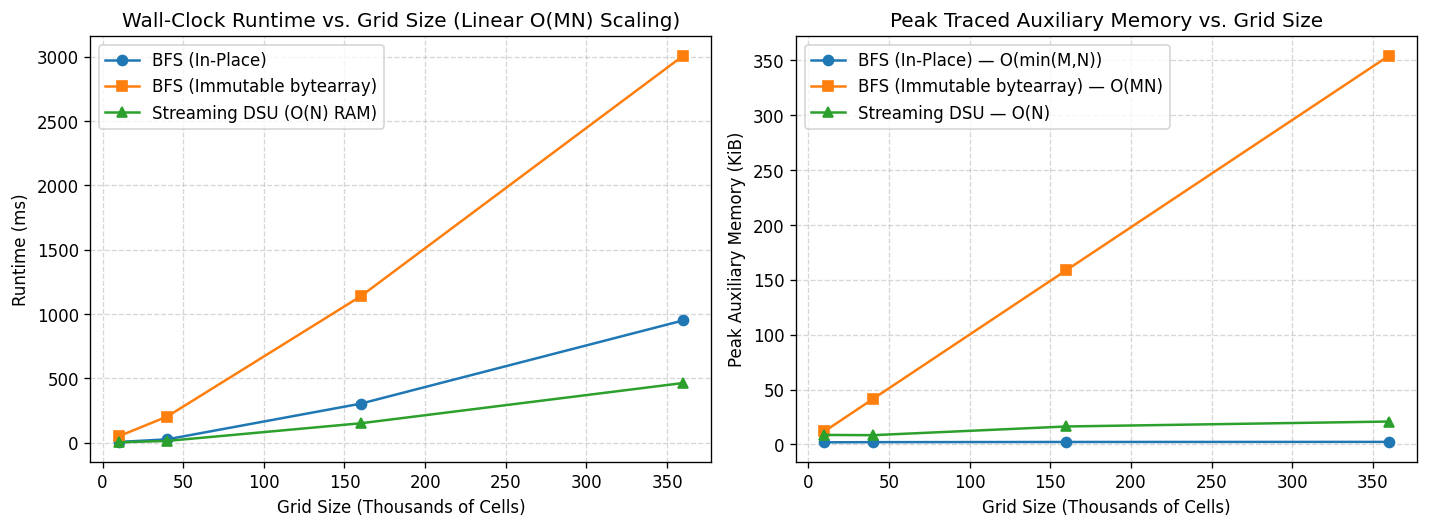

In [6]:
def measure_call(fn, *args, **kwargs) -> tuple[int, float, float]:
    """Measure return value, elapsed wall time (ms), and peak traced memory (KiB)."""
    tracemalloc.start()
    t0 = time.perf_counter()
    result = fn(*args, **kwargs)
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    _, peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return result, elapsed_ms, peak_bytes / 1024.0


# ------------------------------------------------------------------
# Experiment 1: Square grid scaling (runtime & peak auxiliary memory)
# ------------------------------------------------------------------
rng = random.Random(2026)
sizes = [100, 200, 400, 600]
bench_results: list[dict[str, float | int]] = []

print(f"{'Grid':>10} | {'Cells':>8} | {'BFS InPl (ms / KiB)':>22} | {'BFS Imm (ms / KiB)':>22} | {'Stream DSU (ms / KiB)':>23}")
print("-" * 97)

for n in sizes:
    base_grid = [[1 if rng.random() < 0.5 else 0 for _ in range(n)] for _ in range(n)]

    # Prepare a separate mutable copy before starting tracemalloc for bfs_inplace
    grid_for_inplace = [row[:] for row in base_grid]
    c1, t_inp, m_inp = measure_call(count_islands_bfs, grid_for_inplace, mutate_in_place=True, validate=False)
    c2, t_imm, m_imm = measure_call(count_islands_bfs, base_grid, mutate_in_place=False, validate=False)
    c3, t_dsu, m_dsu = measure_call(count_islands_streaming_dsu, base_grid, validate=False)
    assert c1 == c2 == c3

    bench_results.append({
        "n": n,
        "cells": n * n,
        "t_inp": t_inp, "m_inp": m_inp,
        "t_imm": t_imm, "m_imm": m_imm,
        "t_dsu": t_dsu, "m_dsu": m_dsu,
    })
    print(
        f"{f'{n}x{n}':>10} | {n*n:>8,d} | "
        f"{t_inp:>8.1f} ms / {m_inp:>6.1f} KiB | "
        f"{t_imm:>8.1f} ms / {m_imm:>6.1f} KiB | "
        f"{t_dsu:>8.1f} ms / {m_dsu:>6.1f} KiB"
    )

# ------------------------------------------------------------------
# Experiment 2: Out-of-core streaming memory constancy (fixed N=200, growing M)
# ------------------------------------------------------------------
print("\nOut-of-Core Streaming Test (Fixed width N=200, rows generated lazily):")
print(f"{'Dimensions':>12} | {'Total Cells':>12} | {'Islands':>8} | {'Time (ms)':>10} | {'Peak RAM (KiB)':>14}")
print("-" * 68)

stream_N = 200
for stream_M in (500, 2000, 8000):
    def _lazy_stream(m: int = stream_M, n: int = stream_N) -> Iterator[list[int]]:
        local_rng = random.Random(7)
        for _ in range(m):
            yield [1 if local_rng.random() < 0.5 else 0 for _ in range(n)]

    islands, t_ms, peak_kib = measure_call(count_islands_streaming_dsu, _lazy_stream(), validate=False)
    print(f"{f'{stream_M}x{stream_N}':>12} | {stream_M * stream_N:>12,d} | {islands:>8,d} | {t_ms:>10.1f} | {peak_kib:>14.2f}")

# ------------------------------------------------------------------
# Visualization of Runtime & Auxiliary Memory Scaling
# ------------------------------------------------------------------
if HAS_MATPLOTLIB:
    cells_k = [r["cells"] / 1000.0 for r in bench_results]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax1.plot(cells_k, [r["t_inp"] for r in bench_results], marker="o", label="BFS (In-Place)")
    ax1.plot(cells_k, [r["t_imm"] for r in bench_results], marker="s", label="BFS (Immutable bytearray)")
    ax1.plot(cells_k, [r["t_dsu"] for r in bench_results], marker="^", label="Streaming DSU (O(N) RAM)")
    ax1.set_title("Wall-Clock Runtime vs. Grid Size (Linear O(MN) Scaling)")
    ax1.set_xlabel("Grid Size (Thousands of Cells)")
    ax1.set_ylabel("Runtime (ms)")
    ax1.grid(True, linestyle="--", alpha=0.5)
    ax1.legend()

    ax2.plot(cells_k, [r["m_inp"] for r in bench_results], marker="o", label="BFS (In-Place) — O(min(M,N))")
    ax2.plot(cells_k, [r["m_imm"] for r in bench_results], marker="s", label="BFS (Immutable bytearray) — O(MN)")
    ax2.plot(cells_k, [r["m_dsu"] for r in bench_results], marker="^", label="Streaming DSU — O(N)")
    ax2.set_title("Peak Traced Auxiliary Memory vs. Grid Size")
    ax2.set_xlabel("Grid Size (Thousands of Cells)")
    ax2.set_ylabel("Peak Auxiliary Memory (KiB)")
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend()

    plt.tight_layout()
    plt.show()

## 9. Distributed Scalability (Petabyte-Scale Maps) & GitHub Repository Blueprint

### Scaling Beyond a Single Machine (Tile-Based MapReduce / Apache Spark Architecture)
When a geospatial map reaches $10^6 \times 10^6$ ($10^{12}$ cells, ~125 GB even as a 1-bit bitmap), single-node sequential scanning becomes I/O- and CPU-bound. Because our **Streaming DSU** is associative on component merges, it generalizes cleanly to a **2-stage Distributed Tile-Merging Algorithm**:

1. **Map / Partition Phase (Embarrassingly Parallel)**:
   - Partition the $M \times N$ grid into $P$ rectangular tiles of size $B \times B$ (e.g., $4096 \times 4096$ per worker).
   - Each worker runs `StreamingIslandCounter` (or BFS) locally on its tile, producing:
     - `local_island_count`: total islands inside the tile,
     - **4 boundary vectors** (`top`, `bottom`, `left`, `right`), each of length $B$, storing `(tile_id, local_component_id)` for land pixels along the tile perimeter.
   - *Data Reduction*: Only $4B$ boundary entries per tile are shuffled across the network — reducing communication volume from $O(B^2)$ to $O(B)$!
2. **Reduce / Boundary-Merge Phase**:
   - Initialize `global_count = sum(local_island_count for all tiles)` and a global DSU over boundary component IDs.
   - For every pair of adjacent tiles sharing a horizontal or vertical seam, iterate over aligned boundary pixels: whenever both sides are land, call `global_dsu.union(comp_A, comp_B)` and decrement `global_count -= 1` on each distinct merge.
   - For extreme scales, boundary reduction itself can be performed hierarchically in a **divide-and-conquer binary reduction tree** ($O(\log P)$ parallel rounds).

### Recommended GitHub Repository Structure
Since the assignment requests a GitHub repository with a clean Python 3 solution, organize your repository as follows:

```text
counting-islands/
├── README.md                  # Problem analysis, complexity table, usage & benchmarks
├── pyproject.toml             # Packaging metadata, ruff/mypy/pytest configuration
├── src/
│   └── counting_islands/
│       ├── __init__.py        # Exports count_islands, StreamingIslandCounter
│       ├── io_utils.py        # validate_grid, iter_grid_rows_from_stream, parse_grid_from_stream
│       ├── bfs.py             # count_islands_bfs (in-place & flat bytearray immutable)
│       ├── streaming_dsu.py   # StreamingIslandCounter, count_islands_streaming_dsu
│       └── cli.py             # CLI entry point reading M N + Matrix from stdin/file
├── tests/
│   ├── test_official.py       # Provided 3 test cases & stream parser tests
│   ├── test_edge_cases.py     # Empty, 1x1, checkerboard, U-shape, spiral, validation errors
│   └── test_fuzz.py           # Randomized differential tests (BFS vs Streaming DSU)
└── notebooks/
    └── counting_islands_solution.ipynb  # This analytical notebook & benchmark suite
```

### Summary of Key Takeaways
- **4-Connectivity** was formally proven from Test Cases 2 & 3 prior to coding.
- **Zero-Recursion Guarantee**: Both solutions are strictly iterative, eliminating `RecursionError` on adversarial inputs.
- **Memory Optimality**: `bfs_inplace` achieves $O(\min(M, N))$ auxiliary space in RAM; `StreamingIslandCounter` achieves strict **$O(N)$ memory** without mutating the input and supports unbounded streaming row counts $M$.